# Linear algebra 2: Eigenvalues

*Learning path: linear algebra, part 2 of 2.* [Index](README.md) · Previous: [Vectors and matrices](01-vectors-and-matrices.ipynb)

Most vectors are turned by a matrix. A few special directions are only stretched: the **eigenvectors**, and the
stretch factors are the **eigenvalues**. They explain what a matrix does in the long run, which is why they show up in
vibrations, Google's PageRank, population models and quantum mechanics. You will learn

* what eigenvectors and eigenvalues are, and how to find them from $\det(A - \lambda I) = 0$,
* how they **diagonalise** a matrix, and why that makes powers $A^n$ easy,
* the Fibonacci numbers and the golden ratio, from the eigenvalues of a $2\times2$ matrix,
* a Markov chain (tomorrow's weather) and its steady state,
* rotations (complex eigenvalues) and symmetric matrices (perpendicular eigenvectors).

## 1. Directions that are only stretched

In lesson 1 the matrix $A = [2\ 1;\ 1\ 2]$ turned the unit circle into an ellipse. Most arrows changed direction, but
along the diagonal:

In [1]:
A = [2 1; 1 2];
A*[1; 1]
A*[-1; 1]
A*[1; 0]

3
3
-1
1
2
1

$A[1\ 1] = 3\,[1\ 1]$ and $A[-1\ 1] = 1\cdot[-1\ 1]$: these arrows keep their direction and are stretched by 3 and by 1.
$[1\ 0]$ is turned. An **eigenvector** of $A$ is a nonzero $v$ with

$$Av = \lambda v,$$

and the number $\lambda$ is its **eigenvalue**. The plot shows the unit circle, its image (the ellipse), and the two
eigenvector directions: the ellipse's long axis is the eigenvector with $\lambda = 3$ (half-length 3), its short axis the
eigenvector with $\lambda = 1$ (half-length 1). Axes: the coordinates $x$ and $y$ of the plane. The eigen-directions are
drawn as segments `parametric(s*a, s*b, s, -1, 1)` from $-[a\ b]$ to $[a\ b]$:

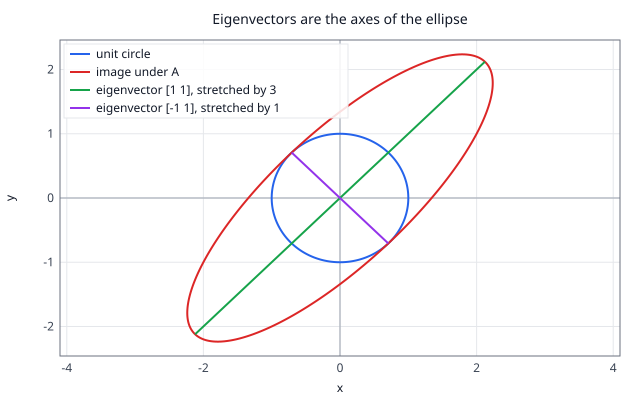

> `title`: A copy of plot p with a title or axis labels.

In [2]:
w = A*[cos(t); sin(t)];
e1 = parametric(3*s/sqrt(2), 3*s/sqrt(2), s, -1, 1);
e2 = parametric(-s/sqrt(2), s/sqrt(2), s, -1, 1);
p = show(parametric(cos(t), sin(t), t, 0, 2*pi), parametric(w(1), w(2), t, 0, 2*pi), e1, e2);
p = legend(p, "unit circle", "image under A", "eigenvector [1 1], stretched by 3", "eigenvector [-1 1], stretched by 1");
labels(title(p, "Eigenvectors are the axes of the ellipse"), "x", "y")

## 2. Finding them

$Av = \lambda v$ means $(A - \lambda I)v = 0$ with $v \ne 0$: the matrix $A - \lambda I$ squashes some direction to 0,
so its determinant is 0 (lesson 1). That gives an equation for $\lambda$, the **characteristic equation**:

$$\det(A - \lambda I) = 0.$$

`charpoly(A, x)` computes $\det(A - xI)$. Its roots are the eigenvalues, and `eig(A)` finds them directly:

In [3]:
charpoly(A, x)
solve(charpoly(A, x) == 0, x)
eig(A)

x^2-4*x+3

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

1	3

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

1	3

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

For each eigenvalue, the eigenvectors are the null space of $A - \lambda I$ (lesson 1). `eye(2)` is the identity
matrix $I$:

In [4]:
null(A - 3*eye(2))
null(A - 1*eye(2))

1
1

> `rref`: Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

-1
1

> `rref`: Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

`eigvec(A)` does both steps and puts the eigenvectors in the columns of a matrix; `[V, D] = eig(A)` gives these
columns `V` together with the diagonal matrix `D` of the matching eigenvalues:

In [5]:
[V, D] = eig(A)

V =
-1	1
1	1
D =
1	0
0	3

## 3. Diagonalising, and powers

In the eigenvector directions $A$ simply multiplies by the eigenvalues. Written with matrices:

$$A = V D V^{-1}.$$

Read from right to left: $V^{-1}$ finds the components along the eigenvectors, $D$ stretches each component by its
eigenvalue, $V$ assembles the result. Then powers are easy, because the $V^{-1}V$ in the middle cancel:
$A^n = V D^n V^{-1}$, and $D^n$ just has $\lambda_1^n$ and $\lambda_2^n$ on the diagonal.

In [6]:
V*D*inv(V)
V*D^5*inv(V)
A^5

2	1
1	2
122	121
121	122
122	121
121	122

For large $n$ the largest eigenvalue wins: $A^n v$ points more and more along the eigenvector with $\lambda = 3$,
whatever $v$ you start with (unless $v$ has no component along it). That is how Google's PageRank finds the most
important web pages: it repeatedly multiplies by a huge matrix and watches which direction wins.

## 4. Fibonacci and the golden ratio

The Fibonacci numbers $0, 1, 1, 2, 3, 5, 8, \ldots$ add the last two to get the next: $F_{n+1} = F_n + F_{n-1}$. As a
matrix step, $[F_{n+1};\ F_n] = M\,[F_n;\ F_{n-1}]$ with $M = [1\ 1;\ 1\ 0]$, so $M^n$ contains $F_n$. `F(n)` picks the
top right entry of $M^n$ (the row $[1\ 0]$ times $M^n$ times the column $[0;\ 1]$):

In [7]:
M = [1 1; 1 0];
M^10
F(n) := [1 0]*M^n*[0; 1];
table([n, F(n)], n, 1, 12)

89	55
55	34
1	1
2	1
3	2
4	3
5	5
6	8
7	13
8	21
9	34
10	55
11	89
12	144

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The eigenvalues of $M$ are the roots of $\lambda^2 = \lambda + 1$: the **golden ratio**
$\varphi = (1 + \sqrt5)/2 \approx 1.618$ and $(1 - \sqrt5)/2 \approx -0.618$.

In [8]:
[V, D] = eig(M)
eval(eig(M))

V =
1/2-sqrt(5)/2	(sqrt(5)+1)/2
1	1
D =
(1-sqrt(5))/2	0
0	(sqrt(5)+1)/2
-0.6180339887498949	1.618033988749895

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Since $|{-0.618}| < 1$, its powers die out, and $F_n$ grows like $\varphi^n$. Exactly, $F_n = (\varphi^n - (1 -
\varphi)^n)/\sqrt5$ (**Binet's formula**, from $M^n = VD^nV^{-1}$), and the ratio of consecutive Fibonacci numbers tends
to $\varphi$. The table has $n$, $F_n$, $F_{n+1}/F_n$ and Binet's formula:

In [9]:
phi = (1 + sqrt(5))/2;
table([n, F(n), eval(F(n + 1)/F(n)), eval((phi^n - (1 - phi)^n)/sqrt(5))], n, 1, 15)

1	1	1.0	1.0
2	1	2.0	1.0
3	2	1.5	2.0
4	3	1.6666666666666667	3.0000000000000004
5	5	1.6	5.000000000000001
6	8	1.625	8.000000000000002
7	13	1.6153846153846154	13.000000000000002
8	21	1.619047619047619	21.000000000000004
9	34	1.6176470588235294	34.00000000000001
10	55	1.6181818181818182	55.000000000000014
11	89	1.6179775280898876	89.00000000000003
12	144	1.6180555555555556	144.00000000000006
13	233	1.6180257510729614	233.00000000000006
14	377	1.6180371352785146	377.00000000000017
15	610	1.618032786885246	610.0000000000003

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

## 5. A Markov chain: tomorrow's weather

Suppose a sunny day is followed by another sunny day with probability 0.9 (and by rain with 0.1), and a rainy day is
followed by sun with probability 0.5. Collect this in a matrix whose column $j$ holds the probabilities for tomorrow if
today is $j$ (column 1: sunny, column 2: rainy):

$$P = \begin{pmatrix} 0.9 & 0.5 \\ 0.1 & 0.5 \end{pmatrix}.$$

If $x$ holds today's probabilities [sun; rain], tomorrow's are $Px$, and in $n$ days $P^nx$. `sun(n, x)` is the
probability of sun after $n$ days, starting from $x$:

In [10]:
P = [9/10 1/2; 1/10 1/2];
sun(n, x) := [1 0]*P^n*x;
S1 = table([n, eval(sun(n, [1; 0]))], n, 0, 12);
S2 = table([n, eval(sun(n, [0; 1]))], n, 0, 12);

The plot has the day $n$ across and the probability of sun up, once starting from a sunny day (blue) and once from a
rainy day (red). The green line is at $5/6$:

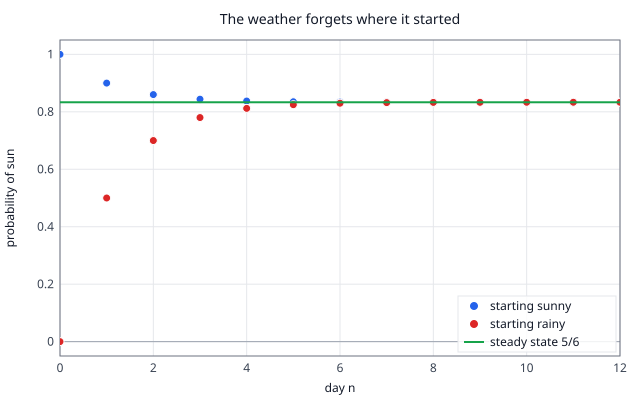

> `title`: A copy of plot p with a title or axis labels.

In [11]:
p = show(scatter(S1, [n p]), scatter(S2, [n p]), plot(5/6 + 0*n, n, 0, 12));
p = legend(p, "starting sunny", "starting rainy", "steady state 5/6");
labels(title(p, "The weather forgets where it started"), "day n", "probability of sun")

After a week the start no longer matters: the chance of sun is $5/6$. That **steady state** is a vector that $P$ leaves
unchanged, $Px = x$: an eigenvector with eigenvalue 1. The other eigenvalue, $0.4$, says how fast the memory fades: the
difference from the steady state shrinks by a factor $0.4$ every day.

In [12]:
[V, D] = eig(P)

V =
-1	5
1	1
D =
2/5	0
0	1

The eigenvector for $\lambda = 1$ is $[5\ 1]$; scaled so its entries add up to 1 it is $[5/6\ \ 1/6]$: in the long run,
5 days in 6 are sunny.

## 6. Rotations and symmetric matrices

A rotation by $90^\circ$ turns every arrow, so no real direction is preserved. Its eigenvalues are complex, $\pm i$:
multiplying by $i$ is a quarter turn in the complex plane ([foundations lesson 6](../foundations/06-complex-numbers.ipynb)).

In [13]:
eig([0 -1; 1 0])

-i	i

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

A **symmetric** matrix ($A = A^T$, equal to its mirror image across the diagonal) is the opposite case: its eigenvalues
are always real and its eigenvectors perpendicular, so it simply stretches along perpendicular axes, as our $A$ did.
This is the **spectral theorem**, and it is what untilted the conics of
[foundations lesson 9](../foundations/09-geometry-and-conics.ipynb). A $3\times3$ example; the dot products of the
eigenvector columns are all 0:

In [14]:
S = [2 0 0; 0 3 4; 0 4 9];
[V, D] = eig(S)
dot(column(V, 1), column(V, 2))
dot(column(V, 1), column(V, 3))
dot(column(V, 2), column(V, 3))

V =
0	1	0
-2	0	1/2
1	0	1
D =
1	0	0
0	2	0
0	0	11
0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

## Summary

* $Av = \lambda v$: eigenvectors are only stretched, by the eigenvalue $\lambda$.
* Eigenvalues solve $\det(A - \lambda I) = 0$ (`charpoly`, `eig`); eigenvectors span `null(A - λ*eye(n))` (`eigvec`).
* `[V, D] = eig(A)`: $A = VDV^{-1}$, so $A^n = VD^nV^{-1}$ and the largest eigenvalue dominates.
* Fibonacci grows like the golden ratio; a Markov chain settles on the eigenvector with eigenvalue 1.
* Rotations have complex eigenvalues; symmetric matrices have real ones with perpendicular eigenvectors.

**Try it:** change the weather so that rain follows rain with probability 0.8. What is the new steady state, and how
fast is it reached? Find the eigenvalues of $[1\ 1;\ 0\ 1]$ (a shear): why is there only one eigenvector direction?
The sequence $a_{n+1} = a_n + 2a_{n-1}$ starts $0, 1, 1, 3, 5, 11, \ldots$: which number does $a_{n+1}/a_n$ approach?

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge Press (2016). Chapter 6.
2. A. A. Markov, "Extension of the law of large numbers to dependent quantities" (in Russian), *Izvestiya Fiz.-Mat. Obsch. Kazan Univ.* 15 (1906) 135–156.
3. J. Binet, "Mémoire sur l'intégration des équations linéaires aux différences finies", *Comptes Rendus* 17 (1843) 559–567.
4. S. Brin and L. Page, "The anatomy of a large-scale hypertextual Web search engine", *Computer Networks and ISDN Systems* 30 (1998) 107–117.